# 02 — Realized-vol estimator comparison

Four estimators (`vrp_lab.volatility.realized`), each with its paper reference
and formula in the docstrings. GBM recovery tests with known σ live in
`tests/test_realized.py`; this notebook is the *empirical* comparison on SPY,
where overnight gaps and drift break each estimator's assumptions differently.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import logging
logging.disable(logging.WARNING)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vrp_lab.config import load_config, PROCESSED, REPORTS
cfg = load_config()
%config InlineBackend.figure_format = "retina"


In [2]:
from vrp_lab.data.yfinance import pull_ohlcv
from vrp_lab.analysis.estimator_compare import run_all, divergence_stats, high_vol_episodes
from vrp_lab.data.cboe import pull_vix_history

spy = pull_ohlcv("SPY", cfg["date_range"]["start"])
vix = pull_vix_history()["close"]
est = run_all(spy, window=21)
divergence_stats(est).round(4)

,mean_level,stdev_of_estimate,mean_gap_vs_cc,max_abs_gap_vs_cc,corr_vs_cc
close_to_close,0.1597,0.1114,0.0000,0.0000,1.0000
parkinson,0.1302,0.0841,-0.0295,0.3799,0.9699
garman_klass,0.1315,0.0861,-0.0282,0.3365,0.9662
rogers_satchell,0.1330,0.0890,-0.0267,0.2993,0.9594
yang_zhang,0.1637,0.1103,0.0039,0.1194,0.9749


Close-to-close is the noisiest (`stdev_of_estimate`); the range-based estimators sit *below* it on SPY because overnight gaps carry variance they cannot see. Yang-Zhang recovers the level (overnight term) while keeping the range estimators' efficiency — the default everywhere in this repo.

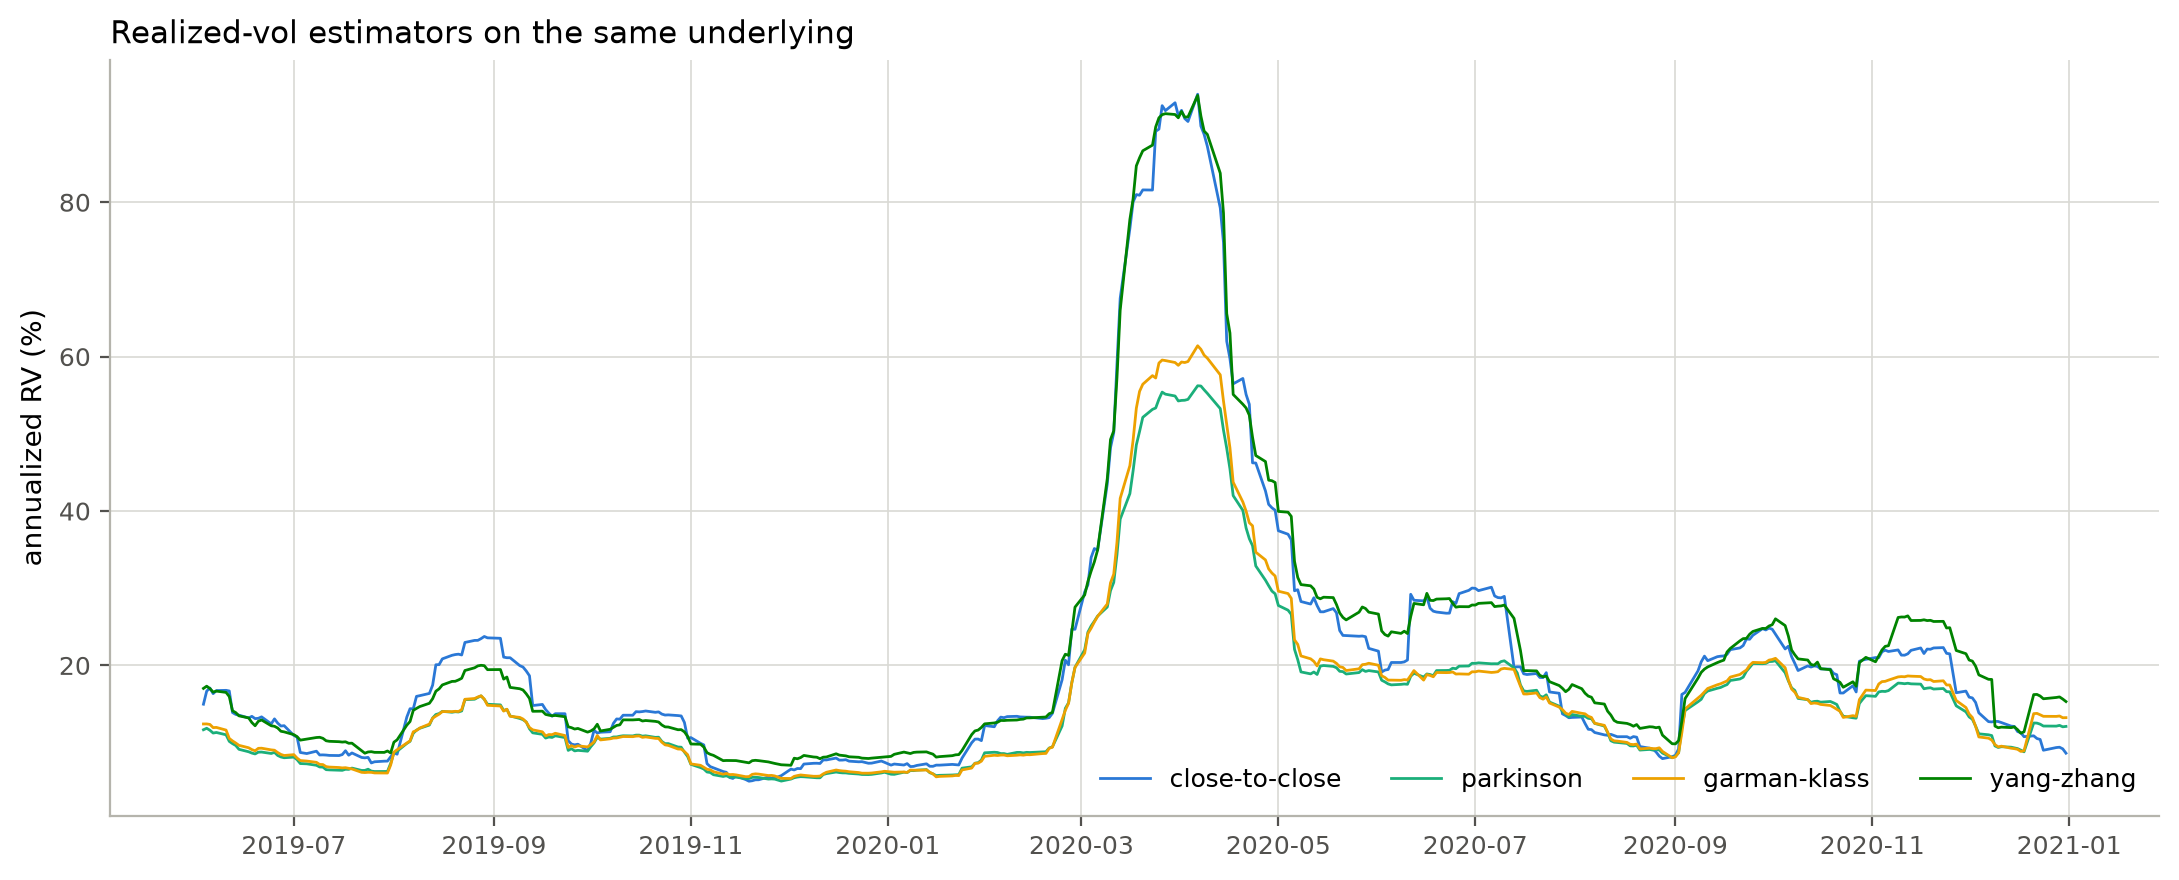

In [3]:
from vrp_lab.visualization.plots import plot_estimator_comparison
sl = slice("2019-06-01", "2020-12-31")
plot_estimator_comparison({k: est[k].loc[sl] for k in
                           ["close_to_close", "parkinson", "garman_klass", "yang_zhang"]});

## Where the choice matters: crisis windows
Restricted to VIX > 25 days, the dispersion across estimators widens to several vol points — enough to flip a marginal VRP signal.

In [4]:
high_vol_episodes(est, vix).round(4)

,mean_level,stdev_of_estimate,mean_gap_vs_cc,max_abs_gap_vs_cc,corr_vs_cc
close_to_close,0.3149,0.1735,0.0000,0.0000,1.0000
parkinson,0.2518,0.1264,-0.0631,0.3799,0.9545
garman_klass,0.2560,0.1317,-0.0589,0.3365,0.9536
rogers_satchell,0.2612,0.1383,-0.0536,0.2993,0.9460
yang_zhang,0.3223,0.1693,0.0075,0.1194,0.9706
